# EXO-INSIGHT — Milestone 4: Candidate Analysis & Scientific Visualisation

**Purpose:** extend the completed M4 scientific validation by comparing the exoplanets with the strongest available evidence of potentially life-supporting conditions.

**Central research question:** *Which known exoplanets have the most favourable measured conditions for potentially supporting life, how reliable is that evidence, and which candidates should be investigated further?*

This notebook builds on the existing M3 and M4 outputs. It does **not** repeat data cleaning or recalculate the Kopparapu habitable-zone model.

## Scientific safeguards

- Habitable-zone membership is a screening indicator, not proof of habitability or life.
- Equilibrium temperature and stellar insolation are complementary measurements; no universal equilibrium-temperature cutoff is applied.
- Planet mass, radius and orbital period are interpreted as supporting context, not independent proof of habitability.
- Mass provenance matters: `Msini` is a minimum-mass quantity, and mass inferred from a mass-radius relationship is not an independent mass measurement.
- Measurement uncertainty is shown explicitly. Missing or zero-valued archive uncertainty is not treated as certainty.
- The candidate prioritisation is **evidence-tiered**, not an invented probability-of-life score.
- The NASA composite table does not establish atmospheric composition, surface liquid water, biosignatures or detailed climate conditions.

**Reference for the existing HZ protocol:** Kopparapu et al. (2014), *Habitable Zones Around Main-sequence Stars: Dependence on Planetary Mass*, ApJL, 787, L29. DOI: [10.1088/2041-8205/787/2/L29](https://doi.org/10.1088/2041-8205/787/2/L29).

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

# Keep visual legends focused on the scientifically relevant screening groups.
def simplify_hz_category(value):
    if value == "Conservative HZ candidate — Class V indicated":
        return "Conservative HZ candidate — Class V indicated"
    if value == "Within conservative HZ flux range — stellar class unverified":
        return "Conservative flux range — stellar class unverified"
    if value == "Within optimistic HZ only":
        return "Optimistic HZ only"
    return "Other / not selected"

PLOT_COLORS = {
    "Conservative HZ candidate — Class V indicated": "#16803c",
    "Conservative flux range — stellar class unverified": "#2563eb",
    "Optimistic HZ only": "#d97706",
    "Other / not selected": "#9ca3af",
}


pandas: 2.2.3
numpy: 2.3.5


## 2. Locate the existing project and load the M3/M4 outputs

Run this notebook from the project root or from its `NOTEBOOKS` folder. The locator searches the current directory and its parents for the existing project structure. If the project is elsewhere, set `PROJECT_ROOT_OVERRIDE` explicitly.

In [2]:
# Optional: set this to the full project directory if automatic discovery fails.
PROJECT_ROOT_OVERRIDE = None  # Example: r"S:\Aivancity\PGE 3\Coding for AI\EXO INSIGHTS"


def locate_project_root():
    candidates = []
    if PROJECT_ROOT_OVERRIDE:
        candidates.append(Path(PROJECT_ROOT_OVERRIDE).expanduser())
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents])
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        required = [
            candidate / "DATA" / "processed" / "exo_insight_preprocessed.csv",
            candidate / "DATA" / "processed" / "milestone4" / "m4_habitable_zone_screening.csv",
            candidate / "DATA" / "processed" / "milestone4" / "m4_candidate_review_queue.csv",
        ]
        if all(path.is_file() for path in required):
            return candidate
    checked = "\n".join(str(p) for p in candidates)
    raise FileNotFoundError(
        "Could not locate the EXO-INSIGHT project. Open this notebook inside the project folder, "
        "or set PROJECT_ROOT_OVERRIDE. Checked:\n" + checked
    )

PROJECT_ROOT = locate_project_root()
DATA_PROCESSED = PROJECT_ROOT / "DATA" / "processed"
M4_DIR = DATA_PROCESSED / "milestone4"
OUTPUT_DIR = M4_DIR / "candidate_analysis"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

M3_PATH = DATA_PROCESSED / "exo_insight_preprocessed.csv"
HZ_PATH = M4_DIR / "m4_habitable_zone_screening.csv"
REVIEW_PATH = M4_DIR / "m4_candidate_review_queue.csv"
PROTOCOL_PATH = M4_DIR / "m4_screening_protocol.json"

m3 = pd.read_csv(M3_PATH)
hz = pd.read_csv(HZ_PATH)
review = pd.read_csv(REVIEW_PATH)
protocol = json.loads(PROTOCOL_PATH.read_text(encoding="utf-8"))

print("Project root:", PROJECT_ROOT)
print("M3 shape:", m3.shape)
print("M4 HZ screening shape:", hz.shape)
print("M4 review queue shape:", review.shape)
print("HZ protocol:", protocol["source"], "|", protocol["model"])

Project root: /mnt/data/exo_audit/EXO INSIGHTS
M3 shape: (6451, 15)
M4 HZ screening shape: (6451, 29)
M4 review queue shape: (254, 32)
HZ protocol: Kopparapu et al. (2014), ApJL 787, L29 | 1 Earth-mass; runaway greenhouse inner edge; maximum greenhouse outer edge


## 3. Validate the handover and merge orbital/physical measurements

M4 screening already contains the scientific HZ classifications and insolation uncertainty assessment. The M3 dataset supplies the selected physical and orbital measurements that were not all retained in the M4 screening export. We merge on the exact planet name and check that this does not multiply or remove screening records.

In [3]:
assert "pl_name" in m3.columns and "pl_name" in hz.columns
assert m3["pl_name"].is_unique, "M3 planet names are expected to be unique for this project export."
assert hz["pl_name"].is_unique, "M4 screening planet names are expected to be unique."

physical_columns = [
    "pl_name", "pl_rade", "pl_bmasse", "pl_eqt", "pl_insol",
    "pl_orbper", "pl_orbsmax", "st_teff", "st_rad", "st_mass",
    "sy_dist", "pl_bmassprov", "disc_year", "discoverymethod", "hostname"
]
physical_columns = [c for c in physical_columns if c in m3.columns]
physical = m3[physical_columns].copy()

# M4 contains some of these fields already. Keep the M4 screening values as authoritative
# for HZ classifications and add only M3 fields that are absent from that export.
add_columns = [c for c in physical.columns if c == "pl_name" or c not in hz.columns]
analysis = hz.merge(physical[add_columns], on="pl_name", how="left", validate="one_to_one")

assert len(analysis) == len(hz) == len(m3) == 6451, "Unexpected row count: inspect the M3/M4 handover."
assert analysis["pl_name"].is_unique

print("Handover validation passed")
print("Rows retained:", len(analysis))
print("M4 rows without a matching M3 record:", int(analysis["hostname"].isna().sum()) if "hostname" in analysis else "hostname already supplied by M4")
display(analysis[[c for c in ["pl_name", "hz_screening_category", "pl_eqt", "pl_insol", "pl_bmasse", "pl_rade", "pl_orbper", "pl_orbsmax"] if c in analysis]].head())

Handover validation passed
Rows retained: 6451
M4 rows without a matching M3 record: 0


,pl_name,hz_screening_category,pl_eqt,pl_insol,pl_bmasse,pl_rade,pl_orbper,pl_orbsmax
0,11 Com b,Outside optimistic HZ flux range,803.26,68.5387,4914.898486,12.2,323.21000,1.178
1,11 UMi b,Outside optimistic HZ flux range,896.43,114.8502,4684.814200,12.3,516.21997,1.530
2,14 And b,Outside optimistic HZ flux range,909.92,115.1634,1131.151301,13.1,186.76000,0.775
3,14 Her b,Outside optimistic HZ flux range,147.32,0.0873,2828.672822,12.5,1766.41000,2.839
4,16 Cyg B b,Conservative HZ candidate — Class V indicated,228.76,0.4540,565.737400,13.5,798.50000,1.660


## 4. Reconfirm the scientific screening landscape

This is a compact handover check, not a new HZ calculation. The categories below retain the exact terminology from M4.

In [4]:
category_summary = (
    analysis["hz_screening_category"]
    .value_counts(dropna=False)
    .rename_axis("hz_screening_category")
    .reset_index(name="planet_count")
)
category_summary["percentage"] = (100 * category_summary["planet_count"] / len(analysis)).round(2)
display(category_summary)

uncertainty_summary = (
    analysis["insol_uncertainty_assessment"]
    .value_counts(dropna=False)
    .rename_axis("insol_uncertainty_assessment")
    .reset_index(name="planet_count")
)
display(uncertainty_summary)

print("Conservative HZ candidates — Class V indicated:", int(analysis["hz_screening_category"].eq("Conservative HZ candidate — Class V indicated").sum()))
print("Conservative HZ flux range — stellar class unverified:", int(analysis["hz_screening_category"].eq("Within conservative HZ flux range — stellar class unverified").sum()))
print("Optimistic HZ only:", int(analysis["hz_screening_category"].eq("Within optimistic HZ only").sum()))

,hz_screening_category,planet_count,percentage
0,Outside optimistic HZ flux range,5468,84.76
1,Not classified — insufficient or out-of-range evidence,596,9.24
2,Within optimistic HZ only,93,1.44
3,Conservative HZ candidate — Class V indicated,89,1.38
4,Within conservative HZ flux range — stellar class unverified,72,1.12
5,Not classified — host Teff outside model range or missing,63,0.98
6,Not classified — zero insolation requires source review,46,0.71
7,Review — evolved-star class indicated,24,0.37


,insol_uncertainty_assessment,planet_count
0,Reported interval outside conservative HZ,4518
1,Uncertainty unavailable or zero-valued in archive,1718
2,Entire reported interval within conservative HZ,123
3,Uncertainty interval overlaps conservative HZ boundary,57
4,Not assessed — host Teff outside model range or missing,35


Conservative HZ candidates — Class V indicated: 89
Conservative HZ flux range — stellar class unverified: 72
Optimistic HZ only: 93


## 5. Visualisation 1 — Habitable-zone position of planets

This is the primary scientific visualisation. The x-axis is host-star effective temperature and the y-axis is stellar insolation in Earth-flux units. The HZ boundary curves are the **star-specific values already calculated in M4**; they are not universal horizontal cutoffs.

The conservative zone lies between the maximum-greenhouse (outer, lower-flux) and runaway-greenhouse (inner, higher-flux) boundaries. The optimistic zone extends from Early Mars to Recent Venus. Only planets with positive measured insolation and an applicable M4 model are plotted.

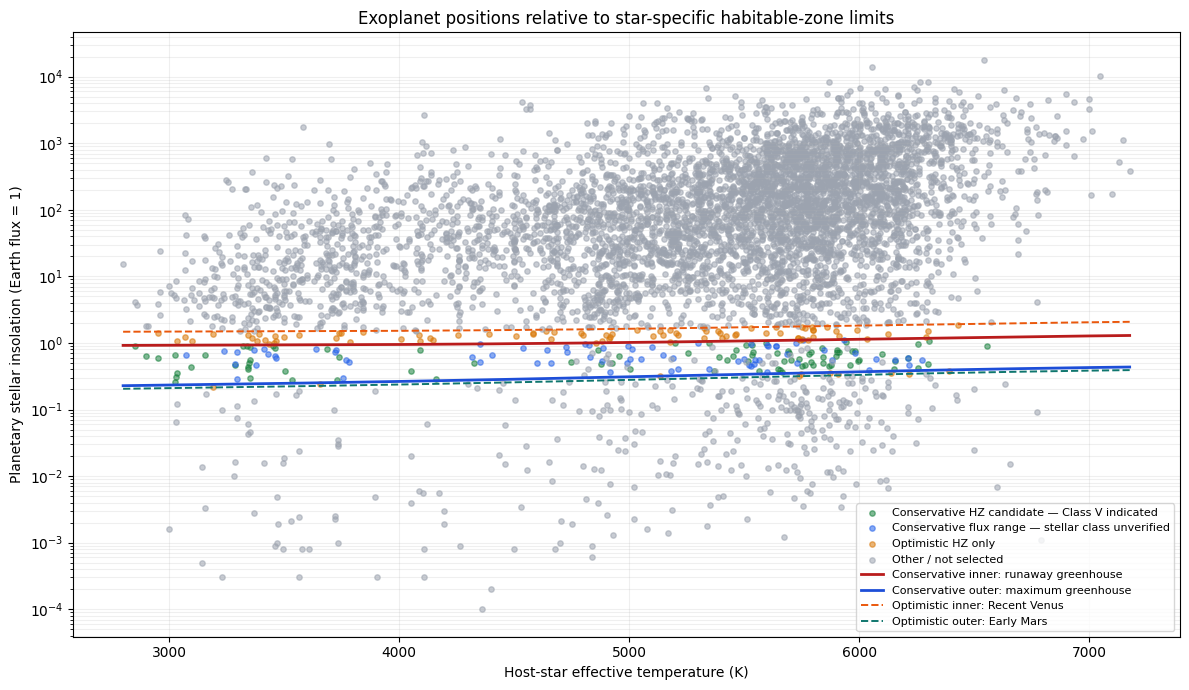

Plotted planets: 5746


In [5]:
plot_hz = analysis.copy()
for col in ["st_teff", "pl_insol", "hz_runaway_greenhouse_flux", "hz_maximum_greenhouse_flux", "hz_recent_venus_flux", "hz_early_mars_flux"]:
    plot_hz[col] = pd.to_numeric(plot_hz[col], errors="coerce")
plot_hz = plot_hz.loc[
    plot_hz["hz_model_teff_applicable"].astype(str).str.lower().isin(["true", "1"]) &
    plot_hz["st_teff"].notna() & (plot_hz["pl_insol"] > 0)
].copy()

fig, ax = plt.subplots(figsize=(12, 7))
colors = {
    "Conservative HZ candidate — Class V indicated": "#16803c",
    "Within conservative HZ flux range — stellar class unverified": "#2563eb",
    "Within optimistic HZ only": "#d97706",
    "Outside optimistic HZ flux range": "#9ca3af",
}
plot_hz["plot_group"] = plot_hz["hz_screening_category"].map(simplify_hz_category)
for category, group in plot_hz.groupby("plot_group", dropna=False):
    ax.scatter(group["st_teff"], group["pl_insol"], s=15, alpha=0.55,
               label=str(category), color=PLOT_COLORS.get(category, "#6b7280"))

# Sort rows by stellar temperature before drawing the existing model boundaries.
boundary_data = plot_hz[["st_teff", "hz_runaway_greenhouse_flux", "hz_maximum_greenhouse_flux", "hz_recent_venus_flux", "hz_early_mars_flux"]].dropna().sort_values("st_teff")
if not boundary_data.empty:
    ax.plot(boundary_data["st_teff"], boundary_data["hz_runaway_greenhouse_flux"], color="#b91c1c", lw=2, label="Conservative inner: runaway greenhouse")
    ax.plot(boundary_data["st_teff"], boundary_data["hz_maximum_greenhouse_flux"], color="#1d4ed8", lw=2, label="Conservative outer: maximum greenhouse")
    ax.plot(boundary_data["st_teff"], boundary_data["hz_recent_venus_flux"], color="#ea580c", lw=1.4, ls="--", label="Optimistic inner: Recent Venus")
    ax.plot(boundary_data["st_teff"], boundary_data["hz_early_mars_flux"], color="#0f766e", lw=1.4, ls="--", label="Optimistic outer: Early Mars")

ax.set_yscale("log")
ax.set_xlabel("Host-star effective temperature (K)")
ax.set_ylabel("Planetary stellar insolation (Earth flux = 1)")
ax.set_title("Exoplanet positions relative to star-specific habitable-zone limits")
ax.grid(True, which="both", alpha=0.2)
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_habitable_zone_position.png", dpi=180, bbox_inches="tight")
plt.show()
print("Plotted planets:", len(plot_hz))

**How to interpret:** points between the conservative boundary curves meet the flux criterion of the M4 model. Blue points have conservative flux-range placement but unverified stellar class. Orange points meet only the optimistic flux range. None of these categories establishes surface habitability.

## 6. Visualisation 2 — Equilibrium temperature versus stellar insolation

This compares two complementary indicators. No fixed temperature threshold is imposed because equilibrium temperature depends on assumptions such as albedo and heat redistribution and does not describe the actual surface temperature of a planet.

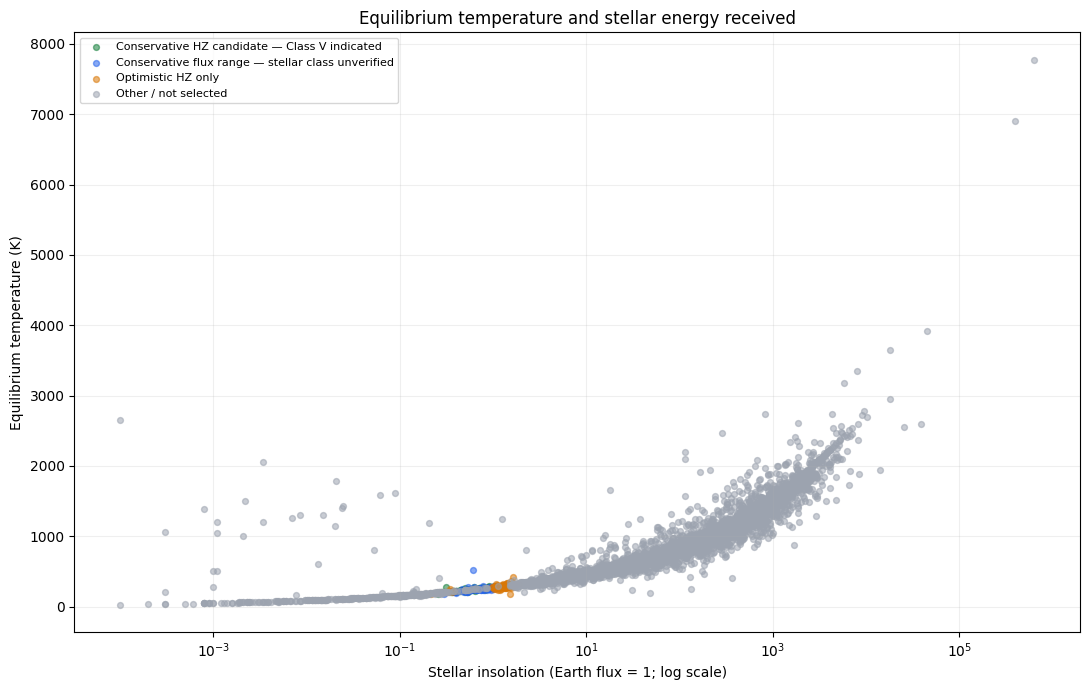

Planets with both positive insolation and equilibrium temperature: 5804


In [6]:
thermal = analysis.copy()
for col in ["pl_eqt", "pl_insol"]:
    thermal[col] = pd.to_numeric(thermal[col], errors="coerce")
thermal = thermal.loc[(thermal["pl_insol"] > 0) & thermal["pl_eqt"].notna()].copy()

fig, ax = plt.subplots(figsize=(11, 7))
thermal["plot_group"] = thermal["hz_screening_category"].map(simplify_hz_category)
for category, group in thermal.groupby("plot_group", dropna=False):
    ax.scatter(group["pl_insol"], group["pl_eqt"], s=18, alpha=0.55,
               label=str(category), color=PLOT_COLORS.get(category, "#6b7280"))
ax.set_xscale("log")
ax.set_xlabel("Stellar insolation (Earth flux = 1; log scale)")
ax.set_ylabel("Equilibrium temperature (K)")
ax.set_title("Equilibrium temperature and stellar energy received")
ax.grid(True, which="both", alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_temperature_vs_insolation.png", dpi=180, bbox_inches="tight")
plt.show()
print("Planets with both positive insolation and equilibrium temperature:", len(thermal))

**How to interpret:** investigate whether the HZ-screened planets also show comparatively moderate equilibrium-temperature estimates. A low or moderate equilibrium temperature alone is not evidence of liquid surface water; atmospheric greenhouse effects and albedo are not resolved by this dataset.

## 7. Visualisation 3 — Planet mass versus radius

Mass and radius provide context for possible planetary composition. This plot uses log scales because exoplanet masses and radii span broad ranges. The Earth reference point is included for orientation only.

**Caution:** mass provenance must be checked. `Msini` values are minimum masses, and mass-radius-inferred values are not independent confirmation of a measured mass.

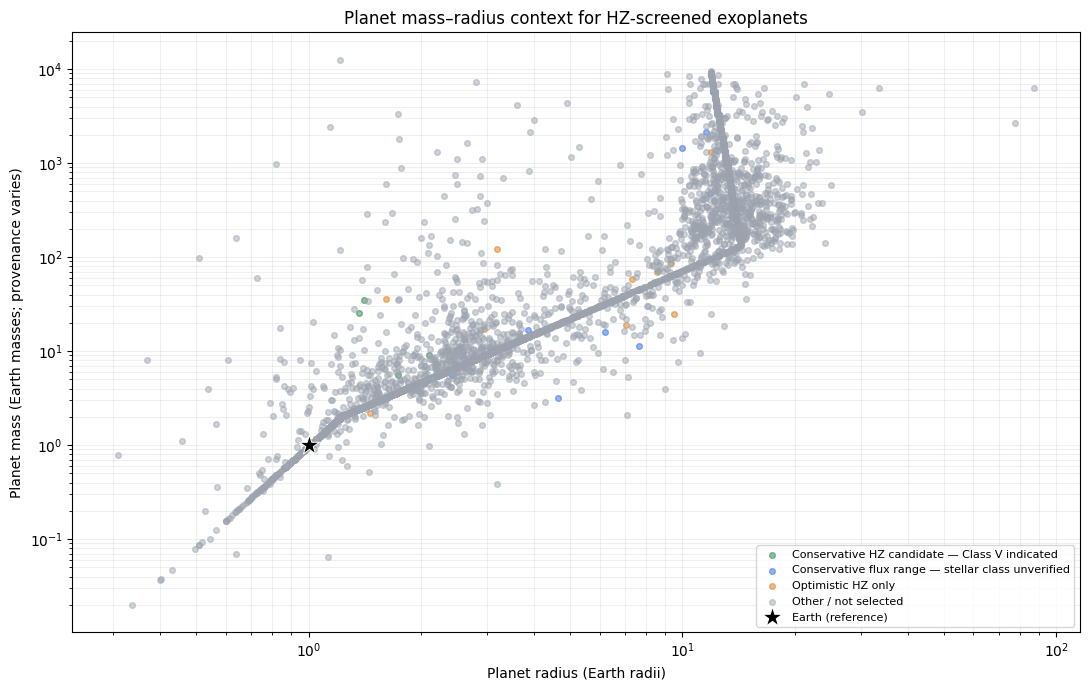

Planets with positive mass and radius: 6378


In [7]:
mr = analysis.copy()
for col in ["pl_bmasse", "pl_rade"]:
    mr[col] = pd.to_numeric(mr[col], errors="coerce")
mr = mr.loc[(mr["pl_bmasse"] > 0) & (mr["pl_rade"] > 0)].copy()

fig, ax = plt.subplots(figsize=(11, 7))
mr["plot_group"] = mr["hz_screening_category"].map(simplify_hz_category)
for category, group in mr.groupby("plot_group", dropna=False):
    ax.scatter(group["pl_rade"], group["pl_bmasse"], s=17, alpha=0.48,
               label=str(category), color=PLOT_COLORS.get(category, "#6b7280"))
ax.scatter([1], [1], marker="*", s=220, color="black", edgecolor="white", linewidth=0.7, label="Earth (reference)", zorder=10)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Planet radius (Earth radii)")
ax.set_ylabel("Planet mass (Earth masses; provenance varies)")
ax.set_title("Planet mass–radius context for HZ-screened exoplanets")
ax.grid(True, which="both", alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_mass_vs_radius.png", dpi=180, bbox_inches="tight")
plt.show()
print("Planets with positive mass and radius:", len(mr))

**How to interpret:** planets closer to Earth's mass and radius may warrant closer physical-characteristics review, but a mass-radius location does not by itself prove a rocky composition. Do not label a planet as Earth-like solely because one or both values are near 1.

## 8. Visualisation 4 — Orbital period and semi-major axis of candidates

This analysis focuses on the M4 candidate review queue. Orbital periods are also converted from Earth days to Earth years (`days / 365.25`) for easier interpretation. Orbital period is descriptive context; a short or long year is not independently a habitability indicator.

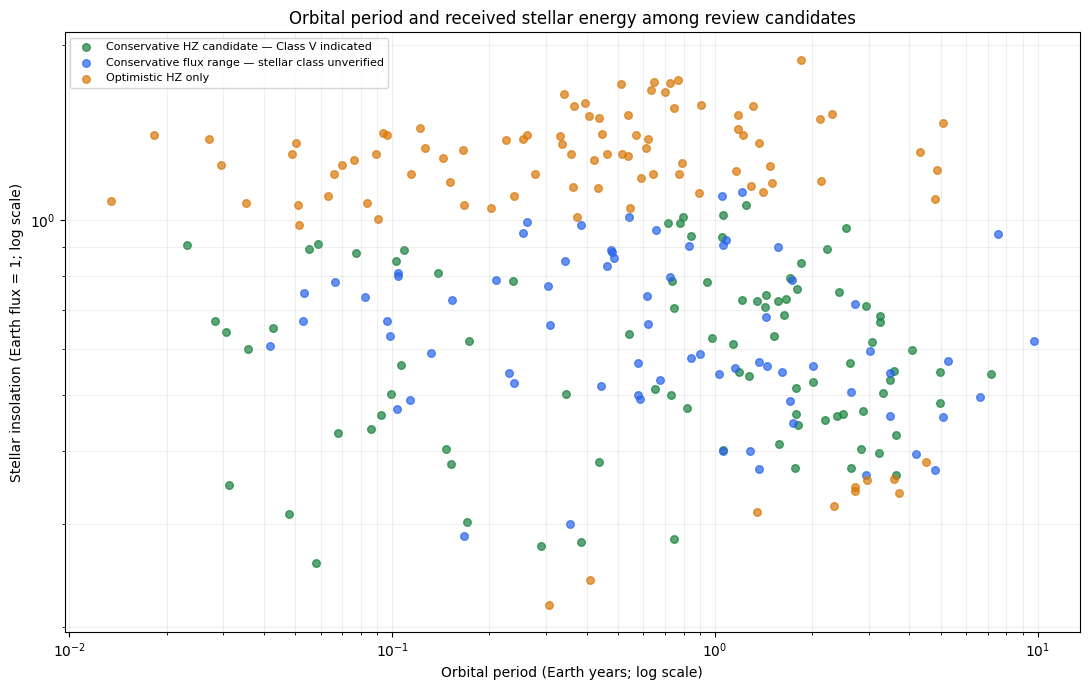

,pl_name,hostname,hz_screening_category,pl_orbper,orbital_period_years,pl_orbsmax,pl_insol
4959,LP 890-9 c,LP 890-9,Conservative HZ candidate — Class V indicated,8.457463,0.023155,0.03984,0.9060
212,GJ 1002 b,GJ 1002,Conservative HZ candidate — Class V indicated,10.346500,0.028327,0.04570,0.6700
5188,Proxima Cen b,Proxima Cen,Conservative HZ candidate — Class V indicated,11.184650,0.030622,0.04848,0.6410
6162,Teegarden's Star c,Teegarden's Star,Conservative HZ candidate — Class V indicated,11.416000,0.031255,0.04550,0.3500
216,GJ 1061 d,GJ 1061,Conservative HZ candidate — Class V indicated,13.066000,0.035773,0.05400,0.6000
6388,Wolf 1069 b,Wolf 1069,Conservative HZ candidate — Class V indicated,15.564000,0.042612,0.06720,0.6520
328,GJ 682 b,GJ 682,Conservative HZ candidate — Class V indicated,17.478000,0.047852,0.08000,0.3125
296,GJ 422 b,GJ 422,Conservative HZ candidate — Class V indicated,20.129000,0.055110,0.11100,0.8928
213,GJ 1002 c,GJ 1002,Conservative HZ candidate — Class V indicated,21.202000,0.058048,0.07380,0.2570
269,GJ 3378 b,GJ 3378,Conservative HZ candidate — Class V indicated,21.450000,0.058727,0.09673,0.9100


In [8]:
candidate_names = set(review["pl_name"].astype(str))
candidates = analysis.loc[analysis["pl_name"].astype(str).isin(candidate_names)].copy()
for col in ["pl_orbper", "pl_orbsmax", "pl_insol"]:
    candidates[col] = pd.to_numeric(candidates[col], errors="coerce")
candidates["orbital_period_years"] = candidates["pl_orbper"] / 365.25

orb = candidates.loc[(candidates["pl_orbper"] > 0) & (candidates["pl_insol"] > 0)].copy()
fig, ax = plt.subplots(figsize=(11, 7))
orb["plot_group"] = orb["hz_screening_category"].map(simplify_hz_category)
for category, group in orb.groupby("plot_group", dropna=False):
    ax.scatter(group["orbital_period_years"], group["pl_insol"], s=30, alpha=0.7,
               label=str(category), color=PLOT_COLORS.get(category, "#6b7280"))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Orbital period (Earth years; log scale)")
ax.set_ylabel("Stellar insolation (Earth flux = 1; log scale)")
ax.set_title("Orbital period and received stellar energy among review candidates")
ax.grid(True, which="both", alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_orbital_period_vs_insolation.png", dpi=180, bbox_inches="tight")
plt.show()

orbital_summary = candidates[[c for c in ["pl_name", "hostname", "hz_screening_category", "pl_orbper", "orbital_period_years", "pl_orbsmax", "pl_insol"] if c in candidates]].copy()
orbital_summary = orbital_summary.sort_values(["hz_screening_category", "orbital_period_years"], na_position="last")
display(orbital_summary.head(25))

## 9. Visualisation 5 — Measurement uncertainty for conservative HZ candidates

NASA's asymmetric uncertainty columns use a positive upper error (`err1`) and a negative lower error (`err2`). We use the absolute magnitude of the lower error for plotting. We do not interpret an absent or zero-valued uncertainty as perfect precision.

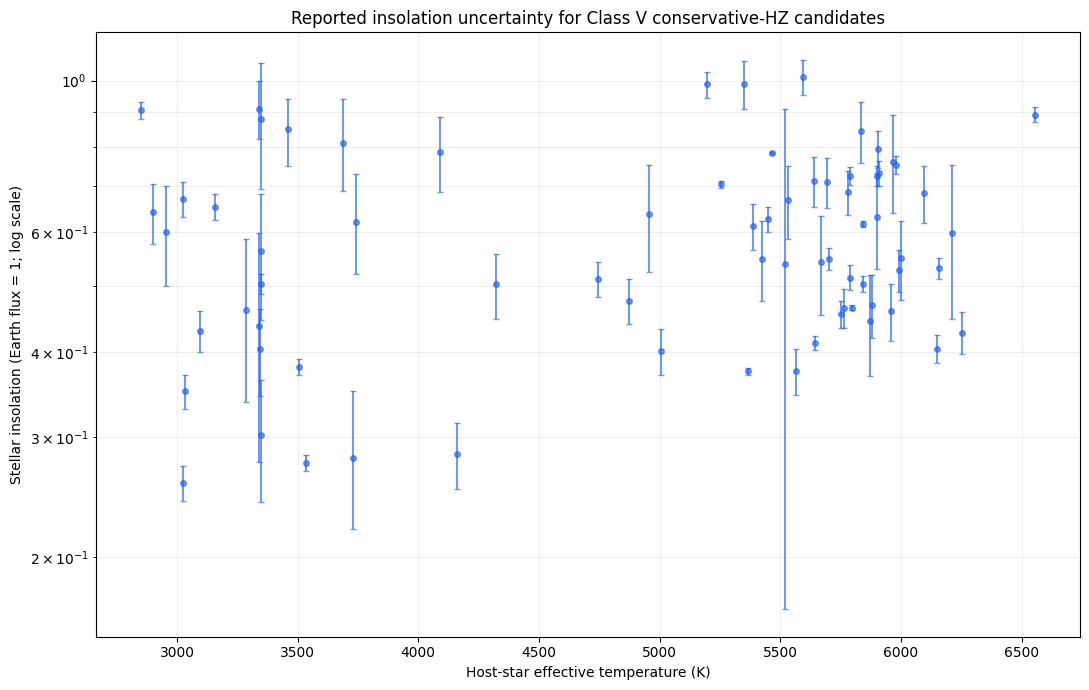

,uncertainty_assessment,planet_count
0,Entire reported interval within conservative HZ,62
1,Uncertainty unavailable or zero-valued in archive,17
2,Uncertainty interval overlaps conservative HZ boundary,10


Class V candidates: 89
Candidates with usable positive asymmetric error bars plotted: 72


In [9]:
class_v = analysis.loc[
    analysis["hz_screening_category"].eq("Conservative HZ candidate — Class V indicated")
].copy()
for col in ["st_teff", "pl_insol", "pl_insolerr1", "pl_insolerr2"]:
    class_v[col] = pd.to_numeric(class_v[col], errors="coerce")
class_v["lower_error_magnitude"] = class_v["pl_insolerr2"].abs()
class_v["upper_error_magnitude"] = class_v["pl_insolerr1"].abs()
error_data = class_v.dropna(subset=["st_teff", "pl_insol", "lower_error_magnitude", "upper_error_magnitude"])
error_data = error_data.loc[
    (error_data["pl_insol"] > 0) &
    (error_data["lower_error_magnitude"] > 0) &
    (error_data["upper_error_magnitude"] > 0)
].copy()

fig, ax = plt.subplots(figsize=(11, 7))
ax.errorbar(
    error_data["st_teff"], error_data["pl_insol"],
    yerr=np.vstack([error_data["lower_error_magnitude"], error_data["upper_error_magnitude"]]),
    fmt="o", markersize=4, alpha=0.65, capsize=2, color="#2563eb"
)
ax.set_yscale("log")
ax.set_xlabel("Host-star effective temperature (K)")
ax.set_ylabel("Stellar insolation (Earth flux = 1; log scale)")
ax.set_title("Reported insolation uncertainty for Class V conservative-HZ candidates")
ax.grid(True, which="both", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_candidate_insolation_uncertainty.png", dpi=180, bbox_inches="tight")
plt.show()

uncertainty_counts = class_v["insol_uncertainty_assessment"].value_counts(dropna=False).rename_axis("uncertainty_assessment").reset_index(name="planet_count")
display(uncertainty_counts)
print("Class V candidates:", len(class_v))
print("Candidates with usable positive asymmetric error bars plotted:", len(error_data))

**Interpretation:** uncertainty intervals entirely inside the conservative HZ provide stronger support for the flux-based classification than intervals that overlap a boundary. Candidates with unavailable/zero-valued uncertainty remain uncertain; they are not treated as exact measurements.

## 10. Evidence-tiered candidate prioritisation

We do not calculate an arbitrary weighted score or call it a probability of life. Instead, candidates are placed into transparent evidence tiers using the existing M4 HZ category and reported insolation-uncertainty assessment.

- **Tier 1:** Class V indicated and the entire reported insolation interval is inside the conservative HZ.
- **Tier 2:** Class V indicated, but the reported interval overlaps a conservative HZ boundary.
- **Tier 3:** Class V indicated, but usable insolation uncertainty is unavailable or zero-valued in the archive.
- **Tier 4:** Conservative flux range, but stellar class is unverified.
- **Tier 5:** Within optimistic HZ only.

These are **HZ-evidence tiers only**, not a complete habitability ranking and not calibrated probabilities of life. A Tier 1 planet can still be a gas giant or have other unfavourable/unknown properties. We therefore assess mass, radius, orbital data and provenance separately in the next section. Within each tier, records are not given an artificial numerical rank.

In [10]:
def assign_evidence_tier(row):
    category = row.get("hz_screening_category", "")
    uncertainty = row.get("insol_uncertainty_assessment", "")
    if category == "Conservative HZ candidate — Class V indicated":
        if uncertainty == "Entire reported interval within conservative HZ":
            return "Tier 1 — Class V + uncertainty interval inside conservative HZ"
        if uncertainty == "Uncertainty interval overlaps conservative HZ boundary":
            return "Tier 2 — Class V + uncertainty overlaps HZ boundary"
        if uncertainty == "Uncertainty unavailable or zero-valued in archive":
            return "Tier 3 — Class V + uncertainty unavailable/zero-valued"
        return "Tier 3 — Class V + uncertainty requires review"
    if category == "Within conservative HZ flux range — stellar class unverified":
        return "Tier 4 — Conservative flux range; stellar class unverified"
    if category == "Within optimistic HZ only":
        return "Tier 5 — Optimistic HZ only"
    return None

analysis["evidence_tier"] = analysis.apply(assign_evidence_tier, axis=1)

candidate_fields = [
    "pl_name", "hostname", "evidence_tier", "hz_screening_category",
    "insol_uncertainty_assessment", "pl_insol", "pl_insolerr1", "pl_insolerr2",
    "pl_eqt", "pl_bmasse", "pl_rade", "pl_bmassprov", "pl_orbper",
    "pl_orbsmax", "st_teff", "st_spectype", "sy_dist", "disc_year", "discoverymethod"
]
candidate_fields = [c for c in candidate_fields if c in analysis.columns]
ranked_candidates = analysis.loc[analysis["evidence_tier"].notna(), candidate_fields].copy()
ranked_candidates["orbital_period_years"] = pd.to_numeric(ranked_candidates.get("pl_orbper"), errors="coerce") / 365.25

tier_order = {
    "Tier 1 — Class V + uncertainty interval inside conservative HZ": 1,
    "Tier 2 — Class V + uncertainty overlaps HZ boundary": 2,
    "Tier 3 — Class V + uncertainty unavailable/zero-valued": 3,
    "Tier 3 — Class V + uncertainty requires review": 3,
    "Tier 4 — Conservative flux range; stellar class unverified": 4,
    "Tier 5 — Optimistic HZ only": 5,
}
ranked_candidates["tier_order"] = ranked_candidates["evidence_tier"].map(tier_order)
ranked_candidates = ranked_candidates.sort_values(["tier_order", "pl_name"]).drop(columns="tier_order")

tier_summary = ranked_candidates["evidence_tier"].value_counts().rename_axis("evidence_tier").reset_index(name="planet_count")
display(tier_summary)
display(ranked_candidates.head(30))

ranked_candidates.to_csv(OUTPUT_DIR / "m4_evidence_tiered_candidate_prioritisation.csv", index=False)
tier_summary.to_csv(OUTPUT_DIR / "m4_candidate_evidence_tier_summary.csv", index=False)
print("Saved evidence-tiered candidate prioritisation.")

,evidence_tier,planet_count
0,Tier 5 — Optimistic HZ only,93
1,Tier 4 — Conservative flux range; stellar class unverified,72
2,Tier 1 — Class V + uncertainty interval inside conservative HZ,62
3,Tier 3 — Class V + uncertainty unavailable/zero-valued,17
4,Tier 2 — Class V + uncertainty overlaps HZ boundary,10


,pl_name,hostname,evidence_tier,hz_screening_category,insol_uncertainty_assessment,pl_insol,pl_insolerr1,pl_insolerr2,pl_eqt,pl_bmasse,pl_rade,pl_bmassprov,pl_orbper,pl_orbsmax,st_teff,st_spectype,sy_dist,disc_year,discoverymethod,orbital_period_years
4,16 Cyg B b,16 Cyg B,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.4540,0.0203,-0.0203,228.76,565.737400,13.50,Msini,798.50000,1.6600,5750.00,G3 V,21.13970,1996,Radial Velocity,2.186174
32,55 Cnc B c,55 Cnc B,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.4613,0.1241,-0.1241,230.04,5.300000,2.16,Msini,33.74700,0.1300,3286.00,M4.5 V,12.47730,2025,Radial Velocity,0.092394
37,55 Cnc f,55 Cnc,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.9879,0.0432,-0.0432,277.07,44.812000,7.59,Mass,260.58000,0.8020,5198.00,G8 V,12.58550,2007,Radial Velocity,0.713429
77,BD-06 1339 c,BD-06 1339,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.5024,0.0551,-0.0551,261.91,53.000000,8.38,Msini,125.94000,0.4350,4324.00,K7/M0 V,20.26950,2013,Radial Velocity,0.344805
79,BD-08 2823 c,BD-08 2823,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.5117,0.0301,-0.0301,233.85,104.000000,12.50,Msini,237.60000,0.6800,4746.00,K3 V,41.33420,2009,Radial Velocity,0.650513
89,BEBOP-4 AB b,BEBOP-4 A,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.5477,0.0198,-0.0198,239.44,8358.887104,NaN,Mass,1823.50000,3.6340,5701.43,G3 V,234.29400,2025,Radial Velocity,4.992471
212,GJ 1002 b,GJ 1002,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.6700,0.0390,-0.0390,230.90,1.080000,1.03,Msini,10.34650,0.0457,3024.00,M5.5 V,4.84867,2022,Radial Velocity,0.028327
213,GJ 1002 c,GJ 1002,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.2570,0.0150,-0.0150,181.70,1.360000,1.10,Msini,21.20200,0.0738,3024.00,M5.5 V,4.84867,2022,Radial Velocity,0.058048
216,GJ 1061 d,GJ 1061,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.6000,0.1000,-0.1000,242.03,1.670000,1.16,Mass,13.06600,0.0540,2953.00,M5.5 V,3.67278,2020,Radial Velocity,0.035773
246,GJ 251 c,GJ 251,Tier 1 — Class V + uncertainty interval inside conservative HZ,Conservative HZ candidate — Class V indicated,Entire reported interval within conservative HZ,0.4040,0.0590,-0.0590,216.00,3.880000,1.80,Msini,53.64700,0.1960,3342.00,M3.0 V,5.58057,2025,Radial Velocity,0.146877


Saved evidence-tiered candidate prioritisation.


## 11. Candidate profiles: interpret the strongest evidence, not just the category

This table focuses on Tier 1 candidates. It brings together HZ classification, uncertainty, temperature, insolation, mass/radius provenance and orbital characteristics. It is a review table, not a declaration that these planets are habitable.

The table is intentionally not sorted by an invented habitability score. Use it to select candidates for detailed follow-up and published-literature checks.

In [11]:
tier1 = ranked_candidates.loc[
    ranked_candidates["evidence_tier"].str.startswith("Tier 1", na=False)
].copy()
profile_columns = [c for c in [
    "pl_name", "hostname", "pl_insol", "insol_uncertainty_assessment",
    "pl_eqt", "pl_bmasse", "pl_rade", "pl_bmassprov",
    "pl_orbper", "orbital_period_years", "pl_orbsmax", "st_teff", "st_spectype", "sy_dist"
] if c in tier1.columns]

tier1_profiles = tier1[profile_columns].copy()
tier1_profiles = tier1_profiles.sort_values("pl_name")
display(tier1_profiles.head(40))
tier1_profiles.to_csv(OUTPUT_DIR / "m4_tier1_candidate_profiles.csv", index=False)
print("Tier 1 candidate count:", len(tier1_profiles))

# A separate physical-characteristics review list: sorted by measured radius, then mass.
# This is a descriptive ordering only, not a habitability score or a rocky-planet classification.
physical_followup = tier1_profiles.copy()
for col in ["pl_rade", "pl_bmasse"]:
    if col in physical_followup.columns:
        physical_followup[col] = pd.to_numeric(physical_followup[col], errors="coerce")
physical_followup = physical_followup.sort_values(["pl_rade", "pl_bmasse"], na_position="last")
print("Tier 1 candidates with both mass and radius available:", int(physical_followup[["pl_rade", "pl_bmasse"]].notna().all(axis=1).sum()))
print("Smallest-radius Tier 1 candidates for manual physical review (not a habitability ranking):")
display(physical_followup.head(20))
physical_followup.to_csv(OUTPUT_DIR / "m4_tier1_physical_followup_sorted_by_radius.csv", index=False)

,pl_name,hostname,pl_insol,insol_uncertainty_assessment,pl_eqt,pl_bmasse,pl_rade,pl_bmassprov,pl_orbper,orbital_period_years,pl_orbsmax,st_teff,st_spectype,sy_dist
4,16 Cyg B b,16 Cyg B,0.4540,Entire reported interval within conservative HZ,228.76,565.737400,13.50,Msini,798.50000,2.186174,1.6600,5750.00,G3 V,21.13970
32,55 Cnc B c,55 Cnc B,0.4613,Entire reported interval within conservative HZ,230.04,5.300000,2.16,Msini,33.74700,0.092394,0.1300,3286.00,M4.5 V,12.47730
37,55 Cnc f,55 Cnc,0.9879,Entire reported interval within conservative HZ,277.07,44.812000,7.59,Mass,260.58000,0.713429,0.8020,5198.00,G8 V,12.58550
77,BD-06 1339 c,BD-06 1339,0.5024,Entire reported interval within conservative HZ,261.91,53.000000,8.38,Msini,125.94000,0.344805,0.4350,4324.00,K7/M0 V,20.26950
79,BD-08 2823 c,BD-08 2823,0.5117,Entire reported interval within conservative HZ,233.85,104.000000,12.50,Msini,237.60000,0.650513,0.6800,4746.00,K3 V,41.33420
89,BEBOP-4 AB b,BEBOP-4 A,0.5477,Entire reported interval within conservative HZ,239.44,8358.887104,NaN,Mass,1823.50000,4.992471,3.6340,5701.43,G3 V,234.29400
212,GJ 1002 b,GJ 1002,0.6700,Entire reported interval within conservative HZ,230.90,1.080000,1.03,Msini,10.34650,0.028327,0.0457,3024.00,M5.5 V,4.84867
213,GJ 1002 c,GJ 1002,0.2570,Entire reported interval within conservative HZ,181.70,1.360000,1.10,Msini,21.20200,0.058048,0.0738,3024.00,M5.5 V,4.84867
216,GJ 1061 d,GJ 1061,0.6000,Entire reported interval within conservative HZ,242.03,1.670000,1.16,Mass,13.06600,0.035773,0.0540,2953.00,M5.5 V,3.67278
246,GJ 251 c,GJ 251,0.4040,Entire reported interval within conservative HZ,216.00,3.880000,1.80,Msini,53.64700,0.146877,0.1960,3342.00,M3.0 V,5.58057


Tier 1 candidate count: 62
Tier 1 candidates with both mass and radius available: 60
Smallest-radius Tier 1 candidates for manual physical review (not a habitability ranking):


,pl_name,hostname,pl_insol,insol_uncertainty_assessment,pl_eqt,pl_bmasse,pl_rade,pl_bmassprov,pl_orbper,orbital_period_years,pl_orbsmax,st_teff,st_spectype,sy_dist
6162,Teegarden's Star c,Teegarden's Star,0.3500,Entire reported interval within conservative HZ,209.00,1.050,1.02,Msini,11.416000,0.031255,0.04550,3034.0,M7.0 V,3.83078
5188,Proxima Cen b,Proxima Cen,0.6410,Entire reported interval within conservative HZ,218.00,1.055,1.02,Msini,11.184650,0.030622,0.04848,2900.0,M5.5 V,1.30119
212,GJ 1002 b,GJ 1002,0.6700,Entire reported interval within conservative HZ,230.90,1.080,1.03,Msini,10.346500,0.028327,0.04570,3024.0,M5.5 V,4.84867
6388,Wolf 1069 b,Wolf 1069,0.6520,Entire reported interval within conservative HZ,250.10,1.260,1.08,Msini,15.564000,0.042612,0.06720,3158.0,M5.0 V,9.58341
213,GJ 1002 c,GJ 1002,0.2570,Entire reported interval within conservative HZ,181.70,1.360,1.10,Msini,21.202000,0.058048,0.07380,3024.0,M5.5 V,4.84867
216,GJ 1061 d,GJ 1061,0.6000,Entire reported interval within conservative HZ,242.03,1.670,1.16,Mass,13.066000,0.035773,0.05400,2953.0,M5.5 V,3.67278
320,GJ 667 C f,GJ 667 C,0.5633,Entire reported interval within conservative HZ,NaN,2.700,1.45,Msini,39.026000,0.106847,0.15600,3350.0,M1.5 V,7.24396
4939,LHS 1140 b,LHS 1140,0.4300,Entire reported interval within conservative HZ,226.00,5.600,1.73,Mass,24.737230,0.067727,0.09460,3096.0,M4.5 V,14.98610
246,GJ 251 c,GJ 251,0.4040,Entire reported interval within conservative HZ,216.00,3.880,1.80,Msini,53.647000,0.146877,0.19600,3342.0,M3.0 V,5.58057
3820,Kepler-296 f,Kepler-296,0.6200,Entire reported interval within conservative HZ,274.00,3.890,1.80,M-R relationship,63.336270,0.173405,0.25500,3740.0,M2 V,167.00000


## 12. Supporting visualisation — exoplanet discovery trends

Discovery trends are retained as context, not as the main scientific result. Discovery counts reflect observational history, survey selection effects and detection methods; they do not measure the frequency of life-supporting planets.

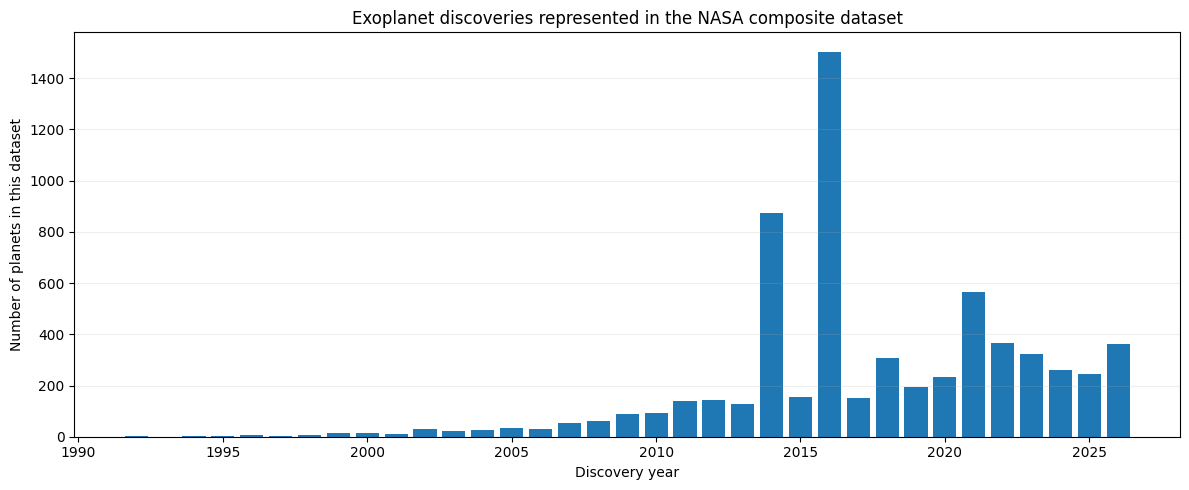

,discovery_method,planet_count
0,Transit,4785
1,Radial Velocity,1204
2,Microlensing,292
3,Imaging,98
4,Transit Timing Variations,29
5,Eclipse Timing Variations,17
6,Orbital Brightness Modulation,9
7,Pulsar Timing,8
8,Astrometry,6
9,Pulsation Timing Variations,2


In [12]:
trend = analysis.copy()
trend["disc_year"] = pd.to_numeric(trend["disc_year"], errors="coerce")
trend = trend.dropna(subset=["disc_year"])
year_counts = trend.groupby("disc_year")["pl_name"].nunique().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(year_counts.index.astype(int), year_counts.values, width=0.8)
ax.set_xlabel("Discovery year")
ax.set_ylabel("Number of planets in this dataset")
ax.set_title("Exoplanet discoveries represented in the NASA composite dataset")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_discovery_trends.png", dpi=180, bbox_inches="tight")
plt.show()

discovery_method_summary = analysis["discoverymethod"].value_counts().rename_axis("discovery_method").reset_index(name="planet_count")
display(discovery_method_summary.head(15))
discovery_method_summary.to_csv(OUTPUT_DIR / "m4_discovery_method_summary.csv", index=False)

## 13. Scientific interpretation checklist

Complete this interpretation after reviewing the actual plots and candidate tables.

1. **HZ evidence:** Which candidates fall within the conservative HZ with the full reported insolation interval inside the boundaries?
2. **Thermal context:** Do those candidates also have equilibrium-temperature estimates that warrant follow-up? Do not apply a universal temperature cutoff.
3. **Planet properties:** Which candidates have both mass and radius available? What is the mass provenance, and is the mass an `Msini` value or inferred value?
4. **Orbital context:** What are the orbital periods in Earth days and years, and what are the semi-major axes? Treat these as descriptive context, not direct habitability evidence.
5. **Measurement reliability:** Which candidates have missing uncertainty, boundary overlap or well-contained uncertainty intervals?
6. **Evidence gaps:** Which leading candidates need published atmospheric observations, climate modelling or other follow-up?

### Limits of the current dataset

The supplied NASA `PSCompPars.csv` composite dataset does not establish atmospheric composition, confirmed surface liquid water, biosignatures or detailed climate conditions. A planet in the HZ can still be airless, too hot/cold at the surface, or otherwise unsuitable for life. Those questions require external observational literature and/or dedicated atmospheric and climate models.

**Conclusion wording to use:** “These planets are promising candidates for further habitability investigation based on the available planetary and stellar measurements.” Do not write “these planets contain life,” “these planets are habitable,” or report a probability of life from this dataset.

## 14. Export and final validation

In [13]:
# Export the principal analysis tables without changing the original M3 or M4 files.
category_summary.to_csv(OUTPUT_DIR / "m4_hz_category_summary.csv", index=False)
uncertainty_summary.to_csv(OUTPUT_DIR / "m4_uncertainty_category_summary.csv", index=False)
orbital_summary.to_csv(OUTPUT_DIR / "m4_candidate_orbital_summary.csv", index=False)

validation = {
    "m3_rows": int(len(m3)),
    "m4_screening_rows": int(len(hz)),
    "analysis_rows": int(len(analysis)),
    "unique_planets": int(analysis["pl_name"].nunique()),
    "review_queue_rows": int(len(review)),
    "tier1_candidates": int((analysis["evidence_tier"].str.startswith("Tier 1", na=False)).sum()),
    "tier2_candidates": int((analysis["evidence_tier"].str.startswith("Tier 2", na=False)).sum()),
    "tier3_candidates": int((analysis["evidence_tier"].str.startswith("Tier 3", na=False)).sum()),
    "tier4_candidates": int((analysis["evidence_tier"].str.startswith("Tier 4", na=False)).sum()),
    "tier5_candidates": int((analysis["evidence_tier"].str.startswith("Tier 5", na=False)).sum()),
    "raw_and_prior_milestone_files_overwritten": False,
    "habitability_probability_calculated": False,
    "plots_created": sorted(p.name for p in FIGURE_DIR.glob("*.png")),
}
(OUTPUT_DIR / "m4_candidate_analysis_validation.json").write_text(json.dumps(validation, indent=2), encoding="utf-8")

assert len(analysis) == 6451
assert analysis["pl_name"].nunique() == 6451
assert validation["tier1_candidates"] == 62, "Unexpected Tier 1 count; inspect the source M4 classification/uncertainty fields."
assert len(validation["plots_created"]) == 6, "Expected six visualisation files."

print("M4 candidate analysis validation passed.")
print(json.dumps(validation, indent=2))
print("Output directory:", OUTPUT_DIR)

M4 candidate analysis validation passed.
{
  "m3_rows": 6451,
  "m4_screening_rows": 6451,
  "analysis_rows": 6451,
  "unique_planets": 6451,
  "review_queue_rows": 254,
  "tier1_candidates": 62,
  "tier2_candidates": 10,
  "tier3_candidates": 17,
  "tier4_candidates": 72,
  "tier5_candidates": 93,
  "raw_and_prior_milestone_files_overwritten": false,
  "habitability_probability_calculated": false,
  "plots_created": [
    "01_habitable_zone_position.png",
    "02_temperature_vs_insolation.png",
    "03_mass_vs_radius.png",
    "04_orbital_period_vs_insolation.png",
    "05_candidate_insolation_uncertainty.png",
    "06_discovery_trends.png"
  ]
}
Output directory: /mnt/data/exo_audit/EXO INSIGHTS/DATA/processed/milestone4/candidate_analysis


## 15. Milestone 4 completion decision

This notebook completes the candidate-focused comparison and visualisation layer of M4. Before moving to ML, review the exported Tier 1 profiles and the interpretation checklist. Any final candidate shortlist should be accompanied by a written reason and explicit caveats.

**Next milestone after M4 sign-off:** implement the selected assignment blocks 4 and 7 (decision model and model learned from data), using carefully defined labels and leakage-safe evaluation. The HZ-derived pseudo-label must not be presented as independent ground truth.